## Stochastic Subspace Descent

In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
from scipy import linalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize._linesearch import scalar_search_armijo
from scipy.optimize import root
from scipy.optimize import rosen, rosen_der
import pycutest
import time

from ssd_maincode import *
#create driver and main files

In [ ]:
#line profiler
# %load_ext line_profiler

## Algorithm: 
$$\vec{x}_{k+1} = \vec{x}_k + \alpha \textbf{P}_k \textbf{P}_k^T \nabla f(\vec{x_k})$$
$P \in R^{d \times l}, l \leq d$.  Note $0 < \alpha < 2 \textit{l}/(d\lambda)$

Haar Distributed random matrix: 
$$ \textbf{P} = \sqrt{d \textit{l}} \textbf{Q} \textbf{I}_{d \times l} \in \mathbb{R}^{d \times l}$$

Convergence rate:   
per Corollary 2.3 from 2019 ssd paper, convergence rate under strong convexity should be linear, where 
$$\mathbb{E} f(x_k) - f* \leq \beta^k (f(x_k) - f*), \quad \beta = 1 - l\gamma / d\lambda$$
where $\gamma$ is the smallest eigenvalue of A, and $\lambda$ is the lipschitz constant of the first derivative. 

Note from 5/15/2026 meeting: finding the $\lambda$ may not always be accessible for all functions. So we implement line search in the for-loop for each alpha, and that should yield better results than guessing. 

Think about what could change about the algorithm for nonlinear least squares function of the form
$$ f(\textbf{x}) = \frac{1}{2} \sum_i r_i(\textbf{x})^2 = \frac{1}{2} ||r_i(\textbf{x})||^2$$
where $\nabla f = J^T \textbf{r}$

## Linesearch For SSD: Wolfe Condition
7/6/2026  
Let $$\phi(t) = f(x_k + t p_k) $$ where $\phi(t): \mathbb{R} \rightarrow \mathbb{R} $  
Let $\Phi(t) \approx \phi(t)$, where $\Phi(t)$ is a quadratic/cubic interpolation of points $\phi(0)$, $\phi(t_1)$, and $\phi'(0)$ (and $\phi(t_2)$ if cubic).   
For SSD, $\phi'(0) = - || p_k||^2 $, so I will modify the scipy code where there's no need to calculate derphi. I will write a function linesearch depending on scipy.optimize.scalar_search_armijo, where then I can fill in the calculation of directional derivative. 

Notes:
* using scipy because it is already the most efficient implementation of linesearch for this method that I know of. Better than writing from scratch.
* using scalar_search_armijo because sufficient decrease condition should be enough, otherwise the curvature condition requires $\phi'$ at each step, largely increase the computational complexity.
* scipy source code reference: https://github.com/scipy/scipy/blob/v1.18.0/scipy/optimize/_linesearch.py#L27
* scalar_search_armijo does sort of backtracking instead of looping through maximum iteration. So it could take a while... need fix?

7/20/2026
Need to: 
* Find a way to find $\mu_k$, number of function evaluation for the algorithm.
* Implement FD method to find directional derivative. 

In [3]:
pycutest.find_problems(constraints='unconstrained', userN=True)

['BOXPOWER',
 'SPIN2LS',
 'TRIDIA',
 'QING',
 'NONCVXU2',
 'DIXON3DQ',
 'MODBEALE',
 'NONDIA',
 'BROYDN7D',
 'QUARTC',
 'DIXMAANC',
 'ARWHEAD',
 'DIXMAANB',
 'SBRYBND',
 'LUKSAN21LS',
 'KSSLS',
 'VANDANMSLS',
 'BROYDN3DLS',
 'SENSORS',
 '10FOLDTRLS',
 'DIXMAANF',
 'TQUARTIC',
 'YATP2CLS',
 'DIXMAANP',
 'DIXMAANG',
 'POWELLSG',
 'SSCOSINE',
 'FLETBV3M',
 'OSCIGRAD',
 'ARGTRIGLS',
 'DIXMAAND',
 'FMINSURF',
 'INDEFM',
 'SROSENBR',
 'SPINLS',
 'VARDIM',
 'SPMSRTLS',
 'TESTQUAD',
 'LUKSAN22LS',
 'CHNROSNB',
 'SCURLY20',
 'GENHUMPS',
 'FMINSRF2',
 'STRTCHDV',
 'SCURLY30',
 'DIXMAANM1',
 'HILBERTA',
 'SINQUAD',
 'SPARSINE',
 'SCHMVETT',
 'CYCLOOCFLS',
 'CHAINWOO',
 'FLETCHBV',
 'FLETCHCR',
 'POWER',
 'SINQUAD2',
 'DIXMAANA1',
 'HILBERTB',
 'COSINE',
 'TOINTGSS',
 'CURLY10',
 'EDENSCH',
 'INTEQNELS',
 'YATP1CLS',
 'BRYBND',
 'EXTROSNB',
 'PRICE3',
 'CRAGGLVY',
 'LUKSAN15LS',
 'CURLY20',
 'BROWNAL',
 'WOODS',
 'MSQRTALS',
 'CYCLIC3LS',
 'ENGVAL1',
 'BROYDNBDLS',
 'LUKSAN17LS',
 'DQRTIC',
 'FLET

In [6]:
#profiling the ssd algo & quick testing
#saga (eta_max = 0.005) works well for DIXMAANI1, CHNRSNBM, EIGENCLS, MSQRTBLS, DIXMAANK, NONDQUAR(neg evals), 
#SCOSINE sorta works. 
#does not work for LUKSAN12LS, TRIGON2 (singular), CURLY30(fx went up), CRAGGLVY (increased)
#stayed flat bc of 0 eigenvalue: SCURLY10
test_prob = "NCB20"
print(pycutest.problem_properties(test_prob))
p = pycutest.import_problem(test_prob)
x0 = p.x0
# %lprun -f ssd fx, xs, linesearch_hist = ssd(p.obj, x, ls = 'on')
seed = 3
#make a for loop for comparing different methods
xs0, fx0, stpsz0, fncall0, failed_counter0 = ssd(p.obj, x0, ls='saga0', max_fn_call=30000, seed=seed)
xs1, fx_1, stpsz1, fncall1, failed_counter1 = ssd(p.obj, x0, ls='saga1', max_fn_call=30000, seed=seed)
xs2, fx_2, stpsz2, fncall2, failed_counter2 = ssd(p.obj, x0, ls='saga2', max_fn_call=30000, seed=seed)
xs3, fx_3, stepsize3, fncall3, failed_counter3 = ssd(p.obj, x0, ls='saga3', max_fn_call=30000, seed=seed)
xs4, fx_4, stepsize4, fncall4, failed_counter4 = ssd(p.obj, x0, ls='armijo', max_fn_call=30000, seed=seed)

xs00, fx00, stpsz00, fncall00, failed_counter00 = ssd(p.obj, x0, ls='saga0', max_fn_call=30000, seed=seed, z_init = 'grad')
xs11, fx_11, stpsz11, fncall11, failed_counter11 = ssd(p.obj, x0, ls='saga1', max_fn_call=30000, seed=seed, z_init = 'grad')
xs22, fx_22, stpsz22, fncall22, failed_counter22 = ssd(p.obj, x0, ls='saga2', max_fn_call=30000, seed=seed, z_init = 'grad')
xs33, fx_33, stepsize33, fncall33, failed_counter33 = ssd(p.obj, x0, ls='saga3', max_fn_call=30000, seed=seed, z_init = 'grad')
xs44, fx_44, stepsize44, fncall44, failed_counter44 = ssd(p.obj, x0, ls='armijo', max_fn_call=30000, seed=seed, z_init = 'grad')

{'objective': 'other', 'constraints': 'unconstrained', 'regular': True, 'degree': 2, 'origin': 'academic', 'internal': False, 'n': 'variable', 'm': 0}


In [ ]:
test_prob = "NCB20"
print(pycutest.problem_properties(test_prob))
p = pycutest.import_problem(test_prob)
x0 = p.x0
# %lprun -f ssd fx, xs, linesearch_hist = ssd(p.obj, x, ls = 'on')
seed = 3
xs33, fx_33, stepsize33, fncall33, failed_counter33 = ssd(p.obj, x0, ls='saga3', max_fn_call=30000, seed=seed, z_init = 'grad')

{'objective': 'other', 'constraints': 'unconstrained', 'regular': True, 'degree': 2, 'origin': 'academic', 'internal': False, 'n': 'variable', 'm': 0}


array([[0.07988453, 0.00117023],
       [0.74945614, 0.09038522],
       [0.07909383, 0.00403368],
       [0.15367302, 0.07826897]])

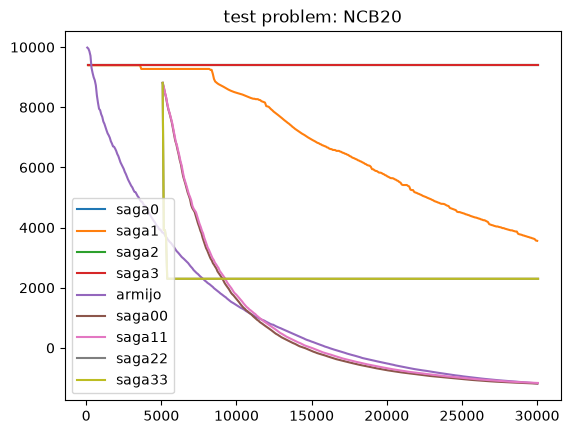

dimension of test problem:  5010
CUTEst counter: {'f': 300471, 'g': 0, 'H': 0, 'Hprod': 0, 'tsetup': 0.0, 'trun': 1139.0, 'c': None, 'cg': None, 'cH': None}


In [7]:
plt.plot(fncall0, fx0, label = 'saga0')
plt.plot(fncall1, fx_1,label = 'saga1')
plt.plot(fncall2, fx_2, label = 'saga2')
plt.plot(fncall3, fx_3, label = 'saga3')
plt.plot(fncall4, fx_4, label = 'armijo')

plt.plot(fncall00, fx00, label = 'saga00')
plt.plot(fncall11, fx_11,label = 'saga11')
plt.plot(fncall22, fx_22, label = 'saga22')
plt.plot(fncall33, fx_33, label = 'saga33')

plt.title("test problem: " + test_prob)
# plt.xlim([0, 500])
plt.legend()
plt.show()
print("dimension of test problem: ", len(x0))
# print('initial: ', fx0[0], 'final: ', fx[-1])
# print('initial: ', fx_1[0], 'final: ', fx_1[-1])
# print('initial: ', fx_2[0], 'final: ', fx_2[-1])
# print('initial: ', fx_3[0], 'final: ', fx_3[-1])
# print('initial: ', fx_4[0], 'final: ', fx_4[-1])
print('CUTEst counter:', p.report())
#why does saga1 not guarantee decrease? 
#look at problems: CHNRSNBM, DIXMAANI1, BOXPOWER, NONDQUAR, CURLY30, CRAGGLVY\
#find ways to get around computing z initially: find variance of saga that doesn't require computing z
#interesting results: SCOSINE, MANCINO, SPARSQUR, BOX, MOREBV
#armijo wins: LIARWHD,ERRINROS, YATP2LS, NCB20, TOINTGSS(saga doesn't work)

In [13]:
# plt.plot(stepsize33, )
stpsz11

array([[ 0.08058424,  0.00117521],
       [ 0.08818005,  0.00108582],
       [ 0.09216424,  0.00128132],
       [ 0.09234816,  0.00117235],
       [ 0.09596045,  0.00167961],
       [ 0.09907662,  0.00137003],
       [ 0.10345903,  0.00100423],
       [ 0.10649821,  0.0012618 ],
       [ 0.10878308,  0.00121272],
       [ 0.1120658 ,  0.00170569],
       [ 0.11471158,  0.00186764],
       [ 0.11639174,  0.00147288],
       [ 0.12403664,  0.00090144],
       [ 0.12257765,  0.00152885],
       [ 0.13192409,  0.00136537],
       [ 0.13519984,  0.00171092],
       [ 0.13800168,  0.00123847],
       [ 0.14013204,  0.00195545],
       [ 0.14477116,  0.0017333 ],
       [ 0.14771074,  0.00117885],
       [ 0.15401958,  0.00119608],
       [ 0.1559106 ,  0.00119558],
       [ 0.16052698,  0.00089176],
       [ 0.15881756,  0.0003565 ],
       [ 0.16446739,  0.00068289],
       [ 0.15914565,  0.00158283],
       [ 0.16165602,  0.00054885],
       [ 0.15776922, -0.00046552],
       [ 0.16247709,

### Testing using CUTEst Problem Environment
* Documentation for CUTEst: https://jfowkes.github.io/pycutest/_build/html/building.html

In [ ]:
#find problem
probs = pycutest.find_problems(constraints='unconstrained', userN=True)
print(probs)

In [ ]:
import os, sys
from contextlib import contextmanager

@contextmanager
def _quiet_fd(fd=2):
    """Silence OS-level fd (2=stderr) around a block — catches compiler/linker stderr
    that bypasses PyCUTEst's quiet=True."""
    stream = sys.stderr if fd == 2 else sys.stdout
    stream.flush()
    saved = os.dup(fd)
    null = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(null, fd); os.close(null)
        yield
    finally:
        stream.flush(); os.dup2(saved, fd); os.close(saved)

def _imp(name, **kw):
    with _quiet_fd(2):
        return pycutest.import_problem(name, quiet=True, **kw)
        
import os, csv, time, io, contextlib, re
import numpy as np

TAUS = (1e-1, 1e-3, 1e-5)

# ---------- evaluation accounting ----------
class BudgetExceeded(Exception): pass

class CountingFn:
    def __init__(self, func, max_evals):
        self.func = func; self.max_evals = max_evals
        self.nfev = 0; self.evals = []; self.vals = []
    def __call__(self, x):
        if self.nfev >= self.max_evals: raise BudgetExceeded
        self.nfev += 1
        v = float(self.func(x))
        self.evals.append(self.nfev); self.vals.append(v)
        return v

def best_so_far(cf):
    evals = np.asarray(cf.evals, dtype=int)
    vals  = np.asarray(cf.vals,  dtype=float)
    fbest = np.empty_like(vals); cur = np.inf
    for i, v in enumerate(vals):
        if np.isfinite(v) and v < cur: cur = v
        fbest[i] = cur
    return evals, fbest

def evals_to_target(evals, fbest, f0, fL, tau):
    target = fL + tau * (f0 - fL)
    hit = np.flatnonzero(fbest <= target)
    return int(evals[hit[0]]) if hit.size else np.inf

def score_ratio(e_off, e_on):
    if np.isinf(e_off) and np.isinf(e_on): return float('nan')
    if np.isinf(e_on):  return float('-inf')
    if np.isinf(e_off): return float('inf')
    return float(np.log10(e_off / e_on))

# ---------- dimension control ----------
def sif_param_options(name):
    """Parse allowed integer SIF parameters from print_available_sif_params (best effort)."""
    buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf):
            pycutest.print_available_sif_params(name)
    except Exception:
        return {}
    opts = {}
    for m in re.finditer(r'(?m)^\s*([A-Za-z]\w*)\s*=\s*(-?\d+)', buf.getvalue()):
        k, v = m.group(1), int(m.group(2))
        if k.lower() == 'default': continue
        opts.setdefault(k, set()).add(v)
    return {k: sorted(vs) for k, vs in opts.items()}

def choose_import(name, n_min, n_max, overrides):
    """Return (problem, n) sized into [n_min, n_max], else (None, reason)."""
    if name in overrides:
        pr = pycutest.import_problem(name, sifParams=overrides[name], quiet=True)
        return pr, int(pr.n)
    tunable = {k: v for k, v in sif_param_options(name).items() if len(v) > 1}
    if not tunable:                                       # fixed size or capture failed
        pr = pycutest.import_problem(name, quiet=True)
        n = int(pr.n)
        return (pr, n) if n_min <= n <= n_max else (None, f'n={n}_no_param')
    param = max(tunable, key=lambda k: len(tunable[k]))   # dimension parameter
    for v in sorted((v for v in tunable[param] if v <= n_max), reverse=True):
        try:
            pr = pycutest.import_problem(name, sifParams={param: v}, quiet=True)
        except Exception:
            continue
        n = int(pr.n)
        if n > n_max: continue                            # multiplier param (n=3M etc.)
        if n < n_min: break                               # smaller v only shrinks n
        return pr, n
    return None, f'{param}_no_fit'

# ---------- run both variants under a shared eval budget ----------
def run_variants(seed, l, budget_factor, evals_cap):
    n  = int(p.n)
    x0 = np.asarray(p.x0, dtype=float)
    f     = lambda x: float(p.obj(x))
    gradf = lambda x: p.obj(x, gradient=True)[1]
    max_evals = int(min(budget_factor * (n + 1), evals_cap))
    l_eff = l if l is not None else min(max(5, int(np.sqrt(n))), n)
    L = estimate_L(p)                                     # <-- add
    curves = {}
    for tag in ('on', 'off'):
        cf = CountingFn(f, max_evals)
        try:
            ssd(cf, gradf, x0.copy(), l=l, ls=tag, max_iter=max_evals + 5,
                seed=seed, L=(L if tag == 'off' else None))   # <-- add
        except BudgetExceeded:
            pass
        curves[tag] = best_so_far(cf)
    return max_evals, l_eff, curves

# ---------- benchmark loop ----------
def run_benchmark(out_csv='ssd_ls_vs_fixed.csv', n_min=10, n_max=120,
                  budget_factor=1000, evals_cap=8000, seed=0, l=None,
                  degenerate_rtol=1e-8, overrides=None, limit=None):
    global p
    overrides = overrides or {}
    probs = sorted(pycutest.find_problems(constraints='unconstrained', userN=True))
    if limit: probs = probs[:limit]
    fields = (['problem','n','l','max_evals','seed','f0','fL','degenerate','status','seconds']
              + [f'{k}_tau{t:g}' for t in TAUS for k in ('evals_on','evals_off','score')])
    new = not os.path.exists(out_csv)
    with open(out_csv, 'a', newline='') as fh:
        w = csv.DictWriter(fh, fieldnames=fields)
        if new: w.writeheader(); fh.flush()
        for name in probs:
            row = {k: '' for k in fields}; row['problem'] = name; row['seed'] = seed
            t0 = time.time()
            try:
                pr, info = choose_import(name, n_min, n_max, overrides)
                if pr is None:
                    row['status'] = f'skip_{info}'
                else:
                    p = pr                                # activate for ssd
                    row['n'] = int(p.n)
                    max_evals, l_eff, curves = run_variants(seed, l, budget_factor, evals_cap)
                    row['l'] = l_eff; row['max_evals'] = max_evals
                    (ev_on, fb_on), (ev_off, fb_off) = curves['on'], curves['off']
                    f0 = fb_on[0]
                    if not np.isfinite(f0):
                        row['status'] = 'bad_f0'
                    else:
                        fL = float(min(fb_on[-1], fb_off[-1]))
                        row['f0'] = f0; row['fL'] = fL
                        degen = (f0 - fL) <= degenerate_rtol * max(1.0, abs(f0))
                        row['degenerate'] = int(degen)
                        for t in TAUS:
                            if degen:
                                e_on = e_off = s = float('nan')
                            else:
                                e_on  = evals_to_target(ev_on,  fb_on,  f0, fL, t)
                                e_off = evals_to_target(ev_off, fb_off, f0, fL, t)
                                s = score_ratio(e_off, e_on)
                            row[f'evals_on_tau{t:g}']  = e_on
                            row[f'evals_off_tau{t:g}'] = e_off
                            row[f'score_tau{t:g}']     = s
                        row['status'] = 'ok'
            except Exception as e:
                row['status'] = f'error:{type(e).__name__}'
            row['seconds'] = round(time.time() - t0, 2)
            w.writerow(row); fh.flush()
            print(f"{name:12s} {row['status']:>16s}  n={row['n']}  {row['seconds']}s")
    return out_csv

def summarize(out_csv):
    import pandas as pd
    df = pd.read_csv(out_csv); ok = df[df['status'] == 'ok']; use = ok[ok['degenerate'] == 0]
    print(f"ok:{len(ok)}  degenerate:{int(ok['degenerate'].sum())}  scored:{len(use)}")
    for t in TAUS:
        s = use[f'score_tau{t:g}'].astype(float); fin = s[np.isfinite(s)]
        print(f"tau={t:g}: ls-on wins {int((s>0).sum())}, fixed wins {int((s<0).sum())}, "
              f"tie {int((s==0).sum())}; median finite {fin.median():+.3f} (n={len(fin)})")

In [ ]:
print(repr(sif_param_options('ARWHEAD')))   # expect {'N': [...]}. If {} => see note below.
run_benchmark()                               # full
summarize('ssd_ls_vs_fixed.csv')

In [ ]:
df = pd.read_csv('ssd_ls_vs_fixed.csv').drop_duplicates(subset='problem', keep='last')
use = df[(df['status'] == 'ok') & (df['degenerate'] == 0)].copy()

tau = '1e-05'
e_on  = pd.to_numeric(use[f'evals_on_tau{tau}'],  errors='coerce')
e_off = pd.to_numeric(use[f'evals_off_tau{tau}'], errors='coerce')

wins = use[e_on < e_off]           # ls-on reached the target in fewer evals
print(wins[['problem', 'n', f'evals_on_tau{tau}', f'evals_off_tau{tau}']]
      .sort_values('n').to_string(index=False))

### visualization

In [ ]:
print(pycutest.problem_properties('DIXMAANB'))
p = pycutest.import_problem('DIXMAANB')
x = p.x0

fx_ls, xs_ls, ls_hist = ssd(p.obj, p.grad, x, ls = 'on')
# %lprun -f ssd fx, xs, linesearch_hist = ssd(p.obj, p.grad, x, max_iter = int(1e4) )
print(f'size of x: {x.size}')
print("with linesearch")
print(fx_ls[0], '→', fx_ls[-1])
print(p.report())

#without linesearch
L = estimate_L(lambda v: p.hprod(v, x=x), x.size)
fx, xs, _ = ssd(p.obj, p.grad, x, ls = 'off', L = 2*L)
print("without linesearch")
print(fx[0], '→', fx[-1])
print(p.report())

fig, ax = plt.subplots()
ax.semilogy(fx_ls, label = 'with linesearch')
ax.semilogy(fx, label = 'without linesearch')
ax.legend()
plt.show()

### Comparing SSD-LN to SPSA
Simultaneous Perturbation Stochastic Approximation: 
$$ \theta_{k+1} = \theta_k + a_k g_k(\theta_k) $$
where $g_k$ is defined with a perturbation vector $\Delta$, and that is the main feature of the algorithm. SPSA is at a major disadvantage when there's no noise in data. For n iterations, the cost is 2n (whereas FDSA is n(p+1)). Recommended to use h (in SSD FD gradient calculation) = c's floor (in spsa_gains) to have the same FD bias. 

In [ ]:
#used ai to translate the matlab code to python
def spsa_gains(loss, theta, step, gavg, expected_evals, noise_sd, NL, alpha=0.602, seed=0):
    '''
    Spall's semi-automatic gain selection for SPSA.
    Computes a, A, c for gains a_k = a/(k+1+A)^alpha, c_k = c/(k+1)^0.101.
    Assumes Rademacher (+/-1) perturbations.

    Parameters:
    loss: objective function
    theta: initial point
    step: desired initial magnitude of change in the theta elements (rho)
    gavg: number of SP gradient estimates averaged per iteration
    expected_evals: expected number of loss evaluations in the SPSA run
    noise_sd: standard deviation of measurement noise at theta_0 (0 if noiseless)
    NL: number of loss evaluations to use here; must be divisible by 2*gavg
    alpha: step decay exponent (companion to gamma = 0.101)

    Returns:
    a, A, c
    '''
    rng = np.random.default_rng(seed)
    theta = np.asarray(theta, dtype=float)
    p = theta.size

    if NL%(2 * gavg) != 0:
        raise ValueError("NL must be divisible by 2*gavg")

    A = 0.10 * expected_evals / (2 * gavg) # 10% of iteration count
    c = max(noise_sd / np.sqrt(gavg), 1e-4) # averaging assumes independent noise

    n_estimates = NL // (2 * gavg)
    gbar = np.zeros(p)
    for _ in range(n_estimates):
        ghat = np.zeros(p)
        for _ in range(gavg):
            delta = 2 * rng.integers(0, 2, size=p) - 1
            yplus  = loss(theta + c * delta)
            yminus = loss(theta - c * delta)
            ghat += (yplus - yminus) / (2 * c * delta)
        gbar += np.abs(ghat / gavg)

    meangbar = np.mean(gbar) / n_estimates
    a = step * (A + 1)**alpha / meangbar

    return a, A, c
    
def spsa(obj, theta, a, c, A, max_fn_call = 7000, alpha=0.602, gamma=0.101, theta_min=None, theta_max=None, seed=0):
    '''
    theta: initial x0
    n: number of iterations

    return: 
    x_history, fx_history

    prioritize function call over iterations. stops when either hits. 
    '''
    #function call counter
    f = counted(obj)
    
    rng = np.random.default_rng(seed)
    theta = np.asarray(theta, dtype=float).copy()
    p = theta.size

    x_history = []
    fx_history = []
    fn_call_history = []

    k = 0
    while f.calls[0] <= max_fn_call:
        ak = a / (k + 1 + A)**alpha
        ck = c / (k + 1)**gamma
        delta = 2 * rng.integers(0, 2, size=p) - 1 # Rademacher
        yplus  = f(theta + ck * delta)
        yminus = f(theta - ck * delta)
        ghat = (yplus - yminus) / (2 * ck * delta)
        theta = theta - ak * ghat
        if theta_min is not None or theta_max is not None:
            theta = np.clip(theta, theta_min, theta_max)

        k += 1
        x_history.append(theta)
        fx_history.append(min(yplus, yminus))
        fn_call_history.append(f.calls[0])

    return np.array(x_history), np.array(fx_history), np.array(fn_call_history)

# #testing the spsa algo using CUTEst collection
# n_iter = 1000
# a, A, c = spsa_gains(p.obj, p.x0, 0.1, 1, 2*n_iter, 0.0, 10)
# x_history, fx_history, fn_call_history = spsa(p.obj, x, a, c, A, seed = 341)
# plt.plot(fx_history)
# plt.show()
# print(fx_history[:10])

#### sketch
let t_sp = the number of function calls required to satisfy the convergence test
```
for i in (# of function evaluations):
    ("ssd-ls", p.name, seed): 'fx_history'(monotone decreasing)

def t_sp:
    give the index of the fx that satisfies the call

function for min{t_sp : s in S}
calculate r_sp. 
```

In [ ]:
#performance and data profile
runs = {}
f0 = {}
prob_dims = {}
budget = 500
seeds  = range(1, 11)
problems = pycutest.find_problems(constraints='unconstrained', userN=True)
for prob in problems:
    p = None
    for sp in ({'N': 1000}, {'N': 500}, {'N': 100}, {'N': 50}, None):
        try:
            p = pycutest.import_problem(prob, sifParams=sp)
            break
        except (RuntimeError, AttributeError, ImportError, OSError):
            try:
                pycutest.clear_cache(prob, sifParams=sp)   # drop the bad entry
            except Exception:
                pass
            continue
    if not (50 <= p.n <= 2000):
        continue
        
    x0 = np.array(p.x0)
    f0[p.name] = float(p.obj(x0))
    prob_dims[p.name] = p.n
    for s in seeds:
        _, fx, _, nf = ssd(p.obj, x0, ls='on', max_fn_call=budget, seed=s)
        runs[('ssd-ls', p.name, s)] = (np.minimum.accumulate(fx), nf)

        a, A, c = spsa_gains(p.obj, x0, step=0.1, gavg=1,
                             expected_evals=budget - 10, noise_sd=0.0, NL=10, seed=s)
        _, fx, nf = spsa(p.obj, x0, a, c, A, max_fn_call=budget - 10, seed=s)
        runs[('spsa', p.name, s)] = (np.minimum.accumulate(fx), nf + 10)   # charge the probe

def t_sp(fbest, nf, f0, fL, tau):
    satisfy = np.flatnonzero(fbest <= fL + tau * (f0 - fL)) #index
    return nf[satisfy[0]] if satisfy.size else np.inf   # evaluations, not index

tau = 1e-3
fL = {}
for (solver_name, problem_name, s), (curve, nf) in runs.items():
    v = curve.min()
    if problem_name not in fL or v < fL[problem_name]:
        fL[problem_name] = v

t = {key: t_sp(curve, nf, f0[key[1]], fL[key[1]], tau)
     for key, (curve, nf) in runs.items()}

def perf_profile(t, solver):
    instances = {(pn, sd) for (_, pn, sd) in t}
    r_ps = []
    for pn, sd in instances:
        best = min(t[(sv, pn, sd)] for sv in ("ssd-ls", "spsa"))
        if not np.isfinite(best):
            continue # no solver solved it; uninformative
        r_ps.append(t[(solver, pn, sd)] / best)
    r_ps = np.array(r_ps)
    grid = np.logspace(0, 3, 200)
    return grid, np.array([(r_ps <= r).mean() for r in grid])

def data_profile(t, solver, kappa_max=100, npts=200):
    instances = {(pn, sd) for (_, pn, sd) in t}
    units = np.array([t[(solver, pn, sd)] / (prob_dims[pn] + 1)
                      for pn, sd in instances])
    grid = np.linspace(0, kappa_max, npts)
    return grid, np.array([(units <= k).mean() for k in grid])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for solver in ("ssd-ls", "spsa"):
    grid, rho = perf_profile(t, solver)
    ax[0].semilogx(grid, rho, label=solver)
    grid, d = data_profile(t, solver)
    ax[1].plot(grid, d, label=solver)
ax[0].set_xlabel("performance ratio"); ax[0].set_ylabel("fraction of instances"); ax[0].legend()
ax[1].set_xlabel(r"budget $\kappa$ (units of $n_p+1$)"); ax[1].set_ylabel("fraction of instances"); ax[1].legend()
plt.tight_layout()
plt.show()

## Methodology

### Methodology
Need to: 
* define f such that it satisfies all assumptions outline in (D. Kozak et al.)
* define P
* iterative SSD algorithm with input f, P. Output parameters $\textbf{x}^*$ and plot loss function and convergence. 

Then compare results with other methods: 
- with line search: newton, BFGS(quasi-newton)
- without line search: block coordinate descent

### Objective Functions: 
Quadratic: strong convex
$$f(x) = \frac{1}{2} x^T A x - b^T x $$
* lambda is the spectral norm of A, so alpha can be determined
* gamma is the smallest eigenvalue of A (Rayleigh Quotient proof), so beta can be determined
* exact solution can be determined using linalg.solve

Rosenbrock: non-convex
$$f(x) = \sum_{i=1}^{d-1} [100 (x_{i-1} - x_i^2)^2 + (x_i - 1)^2 ]$$
* $\textbf{x}^* = (1, 1, ..., 1), f^* = 0
* need line search for alpha

Sphere Function: convex
$$f(\textbf{x}) = \sum_{i=1}^n x_i^2$$
* global minimum at 0
* $\lambda = 2$ and $\gamma = 2$

Ackley Function: non-convex
$$f(x_1, x_2) = -20 exp[-0.2\sqrt{0.5(x^2 + y^2)}] - exp[0.5(\cos 2 \pi x + \cos 2 \pi y) ] + e + 20$$
* global minimum at 0

#### Outline the function for objective functions: 
May 2026  
considerations: 
- objective function defined as f, the lambda function.
- if a function has a known lambda, use it. Otherwise do line search on alpha. 
- if a function has a known solution, use it. Otherwise solve using scipy.linalg.solve
- find gamma.
- plot the convergence against strong convex, convex, and non-convex lines.
- build a class? yes

```
def eval(objective function, known lambda=false, f_exact=false, x, l, max_iter=)
    find alpha, lambda, beta, f_exact
    evaluate using ssd()
    plot
    return None
```

In [ ]:
'''these code are from first time writing SSD algorithm and testing it. Learning phase'''
# conv = "strong convex" or "convex" or "nonconvex"
# sol_np needs to be a numpy array
def eval(ObjFnc, x, l, lam=None, sol_np=None, conv='', gamma=None):

    dim = x.shape[0]
    if sol_np is not None:
        f_exact = sol_np
    else:
        #solve a general function. Only solve quadratic rn
        x_exact = linalg.solve(A,b, assume_a = 'pos')
        f_exact = f(x_exact)

    if lam:
        alpha = l /(dim*lam)
        result, x_history = ssd(x, l, ObjFnc, dim, alpha)
    else:
        result, x_history = ssd(x, l, ObjFnc, dim)
        
    print("f (exact) =", f_exact)
    print("final f =", result[-1])
    print("x history =", x_history[0], x_history[-1])
    
    #plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.set_title('log linear plot: convergence rate')
    ax1.semilogy(result - f_exact, color='b', label='ssd')
    
    if conv == "strong convex" or conv == "convex":
        initial_gap = result[0] - f_exact
        k = np.arange(1, len(result) + 1)
        if conv == "strong convex":
            beta = 1 - (l * gamma)/ (dim*lam)
            ax1.semilogy(beta**k * initial_gap, color='r', ls='dashed', label='strong-conv conv. rate (linear)')
        else:
            sublinear_rate = sublinear_rate = initial_gap / k
            ax1.semilogy(sublinear_rate, color='g', ls='dashed', label='convex conv. rate (sublinear)')
            
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("f(x)-f*")
    ax1.legend()
    
    ax2.set_title('linear plot: ssd vs exact')
    ax2.plot(result, color='b', label='ssd')
    ax2.axhline(f_exact, color='g', label='exact', ls='dashed')
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("f(x)")
    ax2.legend()
    
    plt.show()

    return None

'''testing for the original ssd function without CUTEst and improved linesearch. '''
key = jax.random.PRNGKey(0)
x = jax.random.uniform(key, shape=(4))

# # evaluate quadratic
# key = jax.random.PRNGKey(0)
# A = np.random.randn(4,4)
# A = A@A.T + 0.1 * np.eye(4)#A needs to be positive definite
# print(A)
# b = np.array([2, 4, 1, 3])
# quad = lambda x: (0.5) * x.T @ A @ x - b.T @ x
# eval(quad, x, 2, lam = linalg.norm(A, ord=2), conv = "strong convex")

#non-convex function: Rosenbrock. Need to look into non-convex function convergence. 
rosen = lambda x: sum(100*(x[i+1] - x[i]**2)**2 + (1 - x[i])**2 
                  for i in range(len(x)-1))
eval(rosen, x, 2, sol_np=np.array(0))

# # convex function: sphere
# sphere = lambda x: sum(x[i]**2 for i in range(len(x)-1))
# #find lambda and gamma by hand
# eval(sphere, x, 2, lam=2, gamma=2, sol_np=np.array(0), conv="convex")

# #ackley function: non-convex
# x = jnp.array([0.3, 0.3])  
# ackley = lambda x: -20 * jnp.exp(-0.2 * jnp.sqrt(np.mean(x**2))) - jnp.exp(np.mean(jnp.cos(2 * np.pi * x))) + 20 + jnp.e
# eval(ackley, x, 2, sol_np=np.array(0), conv="nonconvex")
# #ackley function seems to be stuck in the local min and doesn't converge to global min, is that to be expected or not? 

## Modified G-N Stochastic Subspace Descent for Nonlinear Least Squares
Oracle: ${r_i(x)}^m_{i=1} = {q^\top \nabla r_i(x)}^m_{i=1} = J(x)q$ where q is a directional derivative. 

We know $r(x_k + p) = r(x_k) + J(x_k)p$ is the residual function. The nonlinear least square problem is then $$ \min_x ||r(x_k) + J(x_k)p||^2_2 $$

Apply $p = Pn$ to the SSD algorithm, where P is a projection matrix of size $d \times l$ where $l < d$. After applying the substitution, we obtain the normal equation 
\begin{equation}
-(JP)^\top r = (JP)^\top (JP) n
\end{equation}
solving for $n^*$ we have 
$$ Pn = p = P(P^\top J^\top J P)^{-1} P^\top J^\top r $$
Let $P = Q \cdot S$, where the column space of P and Q is the same and $S^{-1}$ exists. Then 
$$ p = Q(Q^\top J^\top J Q)^{-1} Q^\top J^\top r $$
Let $\tilde{J} = J \cdot Q$, then 
$$ p = Q ( \tilde{J}^\top \tilde{J} ) ^{-1} \tilde{J}^\top r$$
and the algorithm costs $l$ for $l$ directional derivatives. 

For computing purposes, compute by finding
$$ p = \text{arg} \min_{n \in \mathbb{R}} ||\tilde{J}n - r_x||^2_2$$

### Linesearch Algo: 
 - Armijo Condition: Similar to the original SSD version except $\phi'(0) = J p_k$, which is also already computed in current step. No extra step needed. Using armijo condition.

In [ ]:
def gn_ssd(x, rx, l=None, ls='armijo', max_iter=200, seed=0, amin=1e-10):
    '''
    input: x is the starting point; P is dxl; r the residual function
    Q has Haar distribution
    Assume alpha = 1
    iteration: x = P
    '''

    #initialize counter
    cons = counted(rx)
    dim = len(x)
    rng = np.random.default_rng(seed)

    #return variables
    x_history = []
    fx_history = []
    stepsize_history = []

    #subspace dimension
    dim = len(x)
    if l is None:
        # default choice for subspace:
        l = min([max([5, int(np.sqrt(dim)) ]), dim])
    if l > dim: raise ValueError('subspace dim should be < dimension')
    if l == dim: print(' Are you sure you want l == dim?')

    #define f as a function than a value
    def fobj(z): 
        rz = cons(z) 
        return 0.5*np.dot(rz, rz)
    alpha0 = 1.0
    
    for n in range(max_iter):
        rval = cons(x)
        fval = 0.5 * np.dot(rval, rval)
        
        Z = rng.standard_normal((dim, l))
        P, _ = linalg.qr(Z, mode='economic') #economic mode for finding the QR so it's not a full square matrix

        #J_tild = JQ
        J_tild = np.column_stack(finite_diff_directional_deriv(x, cons, rval, P.T, h=1e-8))
        pk = np.linalg.lstsq(J_tild, - rval, rcond=None)[0]
        direc = P @ pk

        if ls == 'armijo':
            derphi0 = (J_tild.T @ rval) @ pk
            alpha_ls, nfev, phi1 = linesearch(fobj, x, direc, derphi0, old_fval=fval,alpha0=max(alpha0, amin), amin=amin)
            #if it fails
            if alpha_ls is None: 
                alpha_ls, phi1 = 0.0, fval
            else:
                alpha0 = 2.5 * alpha_ls
            stepsize_history.append(alpha_ls)
            fval = phi1
            x = x + alpha_ls * direc
        elif ls is None or ls == 'off': #alpha = 1
            x = x + direc
            fval = float(fval)

        x_history.append(np.array(x))
        fx_history.append(fval)

    return np.array(fx_history), np.array(x_history), np.array(stepsize_history)

In [ ]:
nls_prob = pycutest.find_problems(objective='none', constraints='linear quadratic other', regular=True)
nls_prob[:10]

In [ ]:
#test the gn_ssd algorithm
print(pycutest.problem_properties('CHANDHEQ'))
p = pycutest.import_problem('CHANDHEQ')
x = p.x0

fx_ls, xs_ls, ls_hist = gn_ssd(x, p.cons, ls = 'armijo')
# %lprun -f ssd fx, xs, linesearch_hist = ssd(p.obj, p.grad, x, max_iter = int(1e4) )
print(f'size of x_i: {x.size}')
print("with linesearch")
print(fx_ls[0], '→', fx_ls[-1])

#without linesearch
fx, xs, _ = gn_ssd(x, p.cons)
print("without linesearch")
print(fx[0], '→', fx[-1])
print(p.report())

fig, ax = plt.subplots()
ax.semilogy(fx_ls, label = 'with linesearch')
ax.semilogy(fx, label = 'without linesearch')
ax.legend()
plt.show()

### Algorithm to compare GN-SSD to
* IBCDFO: https://github.com/POptUS/IBCDFO.git
* Cartis' A Randomised Subspace Gauss-Newton Method for Nonlinear Least-Squares (no code tho... would be great comparison)
* DFBGN: https://github.com/numericalalgorithmsgroup/dfbgn (also from the other Cartis paper)

In [ ]:
import ibcdfo

p = pycutest.import_problem('ARGLALE', sifParams={'N': 50, 'M': 100})
n, m = p.n, p.m
X0 = np.asarray(p.x0, dtype=float)
Ffun = p.cons                     # bound method: pinned to THIS p, no late lookup
nf_max = 100 * (n + 1)
Low, Upp = -np.inf*np.ones(n), np.inf*np.ones(n)

# X, F, hF, flag, xk_best = pounders(Ffun, X0, n, nf_max, 1e-13, 0.1, m, Low, Upp)
ibcdfo.run_pounders(Ffun, X0, n, nf_max, 1e-10, 0.1, m, Low, Upp)
print(flag, hF.shape)
print(hF[0], np.dot(Ffun(X0), Ffun(X0)))
f_curve_p = np.minimum.accumulate(hF / 2.0)
print(f_curve_p[0], f_curve_p[-1])  

## 2D Linesearch
For update equation
$$x_{k+1} = x_k - \eta_1 v_1 - \eta_2 v_2$$ 
We have 
$$\phi(\vec{\eta}) = f(x_k - \eta_1 v_1 - \eta_2 v_2)$$
and $\phi \approx \Phi$
Let $\phi$ be quadratic for testing purposes, 
$$\phi(\eta) = \frac{1}{2} \eta^T A \eta + \eta^T b + c = c_1 + c_2 \eta_1 + c_3 \eta_2 + c_4 \eta_1^2 + c_5 \eta_1 \eta_2 + c_5 \eta_2^2$$
where $A \in \mathbb{R}^{2 \times 2} $, $b \in \mathbb{R}^2$, and $c \in \mathbb{R}$
with input A ($A = A^T$), b, c, and $\eta_{max}$. 

$$\nabla \phi(\eta) = \eta^T A + b = 0$$

First compute these points using the quadratic given. Interpolate through $\phi(0, 0)$, $\frac{\partial}{\partial \eta_1}\phi(0, 0)$, $\frac{\partial}{\partial \eta_2}\phi(0, 0)$, $\phi(\eta_{max}, 0)$, $\phi(0, \eta_{max})$, $\phi(\eta_{max}, \eta_{max})$. Compare the interpolated $\Phi$ to $\phi$. 